In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('dane/prognoza_ludnosci.csv', encoding='utf-8')

In [3]:
display(df.columns)

Index(['h3', 'dzielnica', 'pop_2025', 'pop_2026_niski', 'pop_2027_niski',
       'pop_2028_niski', 'pop_2029_niski', 'pop_2030_niski', 'pop_2031_niski',
       'pop_2032_niski', 'pop_2033_niski', 'pop_2034_niski', 'pop_2035_niski',
       'pop_2036_niski', 'pop_2026', 'pop_2027', 'pop_2028', 'pop_2029',
       'pop_2030', 'pop_2031', 'pop_2032', 'pop_2033', 'pop_2034', 'pop_2035',
       'pop_2036', 'pop_2026_wysoki', 'pop_2027_wysoki', 'pop_2028_wysoki',
       'pop_2029_wysoki', 'pop_2030_wysoki', 'pop_2031_wysoki',
       'pop_2032_wysoki', 'pop_2033_wysoki', 'pop_2034_wysoki',
       'pop_2035_wysoki', 'pop_2036_wysoki', 'pop_2036_wariant_gus',
       'mieszkania_w_budowie', 'dryf_roczny_proc', 'dP_2031', 'dP_2036',
       'dP_2031_norm', 'dP_2036_norm'],
      dtype='str')

In [6]:
wybrane = df.filter(regex=r"pop_20_niski", axis=1)

In [7]:
lata = range(2026, 2037)

# Przyrost względem poprzedniego roku: np. 2026 minus 2025
przyrost = pd.DataFrame(
    {
        f"dP_{rok}": df[f"pop_{rok}"] - df[f"pop_{rok - 1}"]
        for rok in lata
    },
    index=df.index,
)

min_w_roku = przyrost.min()
zakres_w_roku = przyrost.max() - min_w_roku

# Gdy wszystkie wartości w danym roku są równe, wynikiem będzie 0
przyrost_norm = przyrost.sub(min_w_roku).div(
    zakres_w_roku.where(zakres_w_roku != 0, 1)
)

przyrost_norm = przyrost_norm.rename(
    columns=lambda kolumna: f"{kolumna}_norm"
)
df[przyrost_norm.columns] = przyrost_norm

In [9]:
df['dP_2028_norm'].head(5)

0    0.156588
1    0.157861
2    0.155952
3    0.154042
4    0.157225
Name: dP_2028_norm, dtype: float64

In [1]:
kolumny_norm = sorted(
    df.filter(regex=r"^dP_20\d{2}_norm$").columns,
    key=lambda kol: int(kol.split("_")[1])
)

# Skumulowany wynik po każdym kolejnym roku, osobno dla każdego h3
wynik = df[["h3"]].join(
    df[kolumny_norm]
      .sum(axis=1)
      .rename(columns=lambda kol: kol.replace("dP_", "skumulowany_dP_"))
)

display(wynik.head())

NameError: name 'df' is not defined

In [16]:
df["wynik_skomulowany"] = df[kolumny_norm].sum(axis=1)

<Axes: title={'center': 'Rozkład skumulowanego przyrostu ludności w latach 2026-2036'}, ylabel='Skumulowany przyrost ludności'>

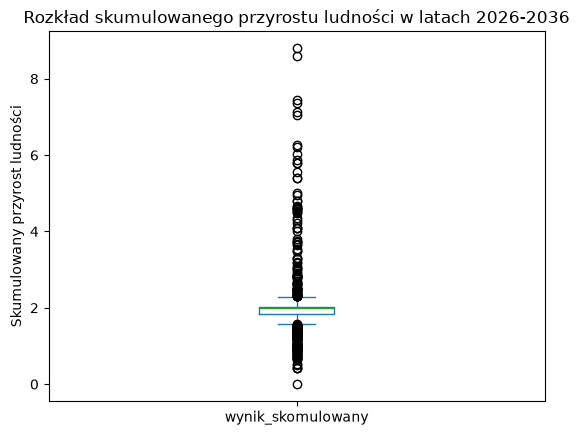

In [18]:
df['wynik_skomulowany'].plot(kind='box', title='Rozkład skumulowanego przyrostu ludności w latach 2026-2036', ylabel='Skumulowany przyrost ludności', xlabel='')

In [19]:
kolumna = "wynik_skomulowany"
min_wynik = df[kolumna].min()
zakres = df[kolumna].max() - min_wynik

df[kolumna + "_norm"] = (
    (df[kolumna] - min_wynik) / zakres
    if zakres != 0
    else 0.0
)

<Axes: title={'center': 'Rozkład skumulowanego przyrostu ludności w latach 2026-2036 (znormalizowany)'}, ylabel='Skumulowany przyrost ludności (znormalizowany)'>

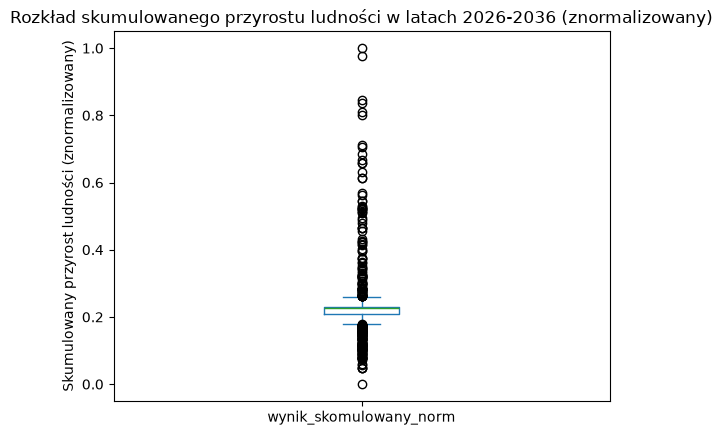

In [20]:
df['wynik_skomulowany_norm'].plot(kind='box', title='Rozkład skumulowanego przyrostu ludności w latach 2026-2036 (znormalizowany)', ylabel='Skumulowany przyrost ludności (znormalizowany)', xlabel='')

In [21]:
result = df[["h3", "dzielnica", "wynik_skomulowany_norm"]].copy()

result.rename(columns={"wynik_skomulowany_norm": "wspolczynnik przyrostu"}, inplace=True)

In [23]:
result.to_csv('dane/wspolczynnik_przyrostu_ludnosci.csv', index=False, encoding='utf-8')

In [ ]:
result.to_csv("dane/wynik_przyrostu_ludnosci_bez_normalizacji.csv", index=False, encoding='utf-8')